# 5. Explainability

*Series:* [1. Data processing](01_data_processing.ipynb) · [2. Exploratory analysis](02_exploratory_analysis.ipynb) · [3. Classification](03_classification.ipynb) · [4. Clustering](04_clustering.ipynb) · **[5. Explainability](05_explainability.ipynb)**

---

What did the model learn, and how much of it should we believe?

Notebook 3 found that four model families perform identically. When performance
cannot choose between models, interpretability becomes the deciding criterion,
which makes this notebook the one that picks the final model.

SHAP is not used here. For a linear model on standardised inputs an additive
decomposition is available in closed form: each feature's contribution to the
log-odds is its coefficient times its standardised value, and those
contributions sum to the prediction exactly. There is nothing for a sampled
approximation of the same quantity to add. For the ensemble, partial dependence
and a fitted surrogate cover the questions that matter.

One caveat governs everything below. These methods explain the model rather
than the disease: they describe how a fitted function responds to its inputs.
Where features are correlated, and `Age`/`Pregnancies` and `BMI`/`SkinThickness`
are, a model can lean on one and ignore the other without either being the real
driver.

In [1]:
import warnings

import numpy as np
import pandas as pd

from pima import evaluate, explain, plots
from pima.data import FEATURES, TARGET, load_processed, split

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plots.use_style()

df = load_processed()
X_train, X_test, y_train, y_test = split(df)

# refit here rather than loading a file saved by notebook 3: no artefact to go
# stale against the code that produced it
lr = evaluate.fit_tuned("logistic_regression", X_train, y_train)
rf = evaluate.fit_tuned("random_forest", X_train, y_train)
print("refitted:", ", ".join(("logistic_regression", "random_forest")))

refitted: logistic_regression, random_forest


## Feature importance in both models

Permutation importance measures the drop in ROC AUC when a feature is shuffled.
It is model-agnostic, so a linear model and a forest can be compared on the same
terms. Coefficients and impurity importances cannot: they are on different
scales and measure different things.

,feature,logistic_regression,random_forest
0,Glucose,0.1919,0.1292
1,BMI,0.0751,0.0578
2,DiabetesPedigreeFunction,0.0213,0.0137
3,Pregnancies,0.0128,-0.0040
4,BloodPressure,0.0091,0.0058
5,Insulin,0.0062,0.0120
6,Age,0.0034,0.0392
7,SkinThickness,0.0006,0.0089


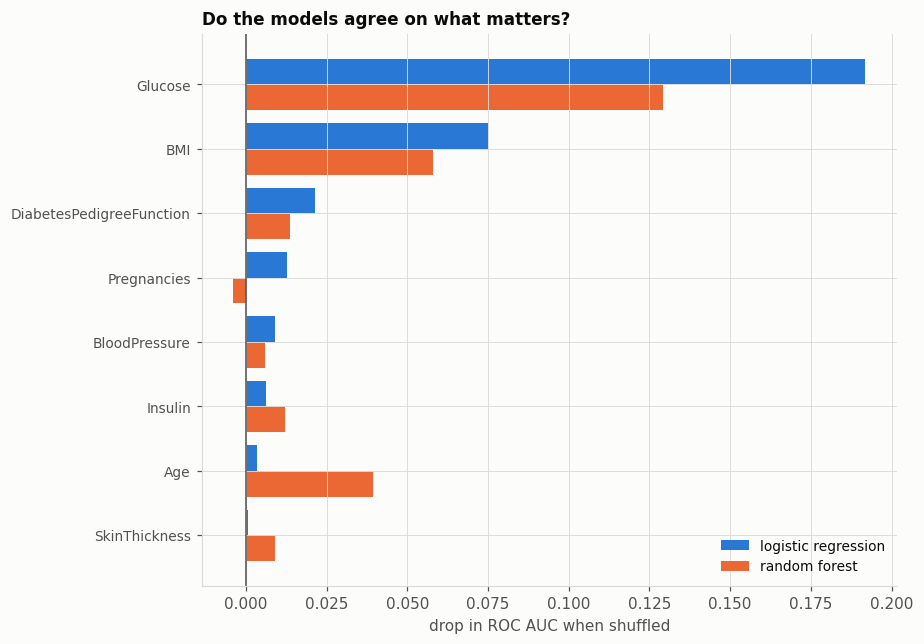

In [2]:
importances = {
    "logistic_regression": evaluate.permutation_importances(lr, X_test, y_test),
    "random_forest": evaluate.permutation_importances(rf, X_test, y_test),
}
comparison = explain.compare_importances(importances)
plots.importance_comparison(comparison)
comparison

The two models agree on `Glucose` and disagree about most of the rest.

Both put `Glucose` far ahead of everything (0.19 and 0.13), with `BMI` a
distant second. After that they diverge:

- `Age`: the forest leans on it more than ten times as heavily as the linear
  model (0.039 against 0.003).
- `Pregnancies`: the linear model uses it (0.013), while shuffling it slightly
  improves the forest (-0.004), so the forest does not use it at all.

`Age` and `Pregnancies` are correlated, as notebook 2's heatmap showed, and the
two models split that shared information differently. The forest can represent
age non-linearly and takes it directly. The linear model cannot, so it partly
routes the same signal through `Pregnancies`. Notebook 2 flagged this as a risk
for interpretation, and here it is.

Two models reach identical accuracy using different features. Neither has found
the explanation, and the data supports more than one account. A narrative built
on a single model's importances is a narrative about that model.

The near-zero importances for `Insulin`, `SkinThickness` and `BloodPressure` in
both models line up with the small effect sizes in notebook 2, and for `Insulin`
with half its values being imputed.

## Uncertainty on the coefficients

A single fit gives a point estimate per coefficient and no sense of how much it
would move on different data. Refitting the whole pipeline on bootstrap
resamples answers that. A coefficient whose interval straddles zero is not
evidence of anything, however confident its point value looks.

In [3]:
coefficients = explain.coefficient_table(lr, X_train, y_train, n_boot=400)
coefficients

,feature,coefficient,ci_low,ci_high,odds_ratio,excludes_zero
0,Glucose,1.046,0.894,1.243,2.846,True
1,BMI,0.435,0.241,0.644,1.545,True
2,Pregnancies,0.395,0.181,0.616,1.485,True
3,DiabetesPedigreeFunction,0.297,0.100,0.500,1.346,True
4,Age,0.157,-0.072,0.408,1.170,False
5,missingindicator_BloodPressure,0.157,-0.021,0.342,1.170,False
6,missingindicator_Insulin,0.141,-0.098,0.376,1.152,False
7,missingindicator_BMI,-0.086,-0.340,0.068,0.917,False
8,SkinThickness,0.077,-0.118,0.304,1.080,False
9,missingindicator_SkinThickness,-0.069,-0.297,0.153,0.933,False


Only four of thirteen coefficients have intervals excluding zero: `Glucose`,
`BMI`, `Pregnancies` and `DiabetesPedigreeFunction`.

`Age`, `SkinThickness`, `BloodPressure`, `Insulin` and all five missing-value
indicators straddle zero. The model is effectively using four features and the
rest are along for the ride. That explains notebook 3's ablation result, where
missing-indicators made no measurable difference: they were never carrying
weight.

Because the features are standardised, the coefficients are directly comparable
to one another: each is the change in log-odds per standard deviation. That
comparison is invalid on raw features, where a coefficient's size mostly
reflects the unit a variable happens to be measured in.

The odds ratios make it readable: **a one-standard-deviation rise in glucose
(about 31 mg/dL) multiplies the odds of diabetes by 2.85** [95% CI 2.44 to 3.47].
`BMI` contributes 1.55 per standard deviation, `Pregnancies` 1.49.

The standing caution applies here too: elevated glucose is close to the
diagnostic criterion for diabetes, so this coefficient is largely recovering a
definition.

## The shape of each learned effect

A coefficient gives a direction and a magnitude but assumes a straight line.
Partial dependence shows the shape of the learned effect, averaged over the
observed distribution of the other features, so each curve answers what would
happen if this patient's glucose were X and everything else stayed as it is.

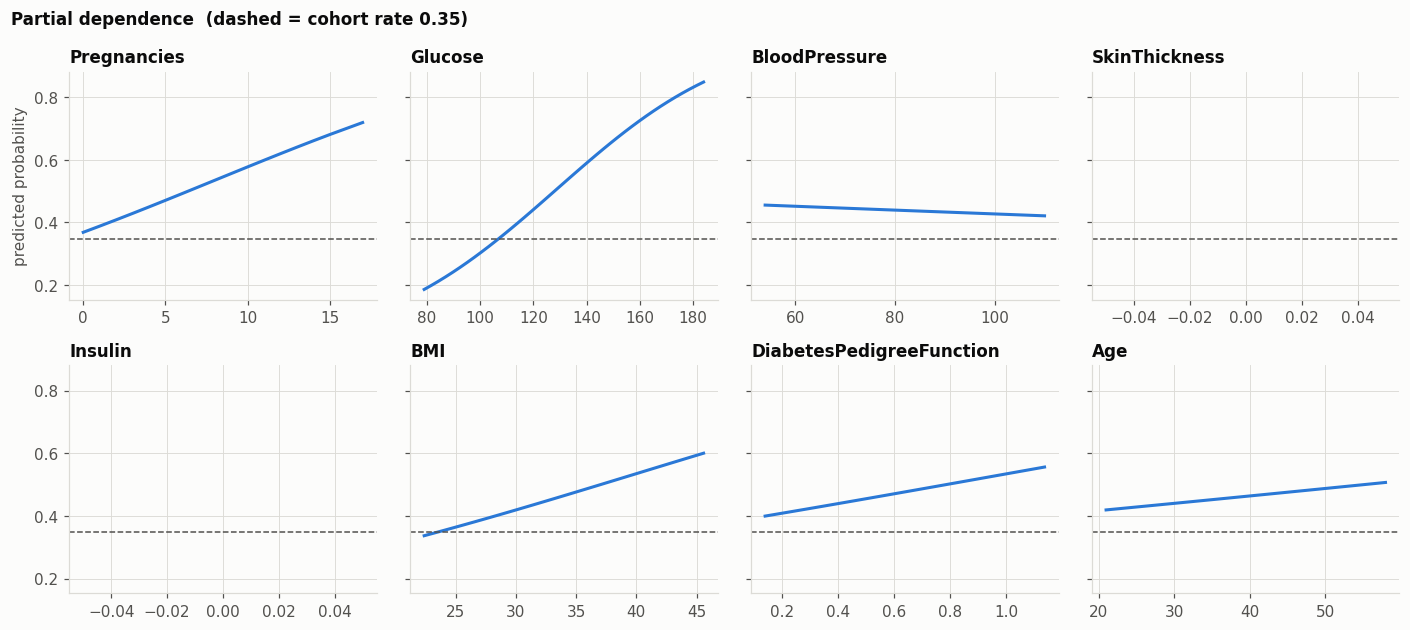

In [4]:
pdp_lr = {f: explain.partial_dependence_frame(lr, X_train, f) for f in FEATURES}
plots.partial_dependence_curves(pdp_lr, base_rate=y_train.mean());

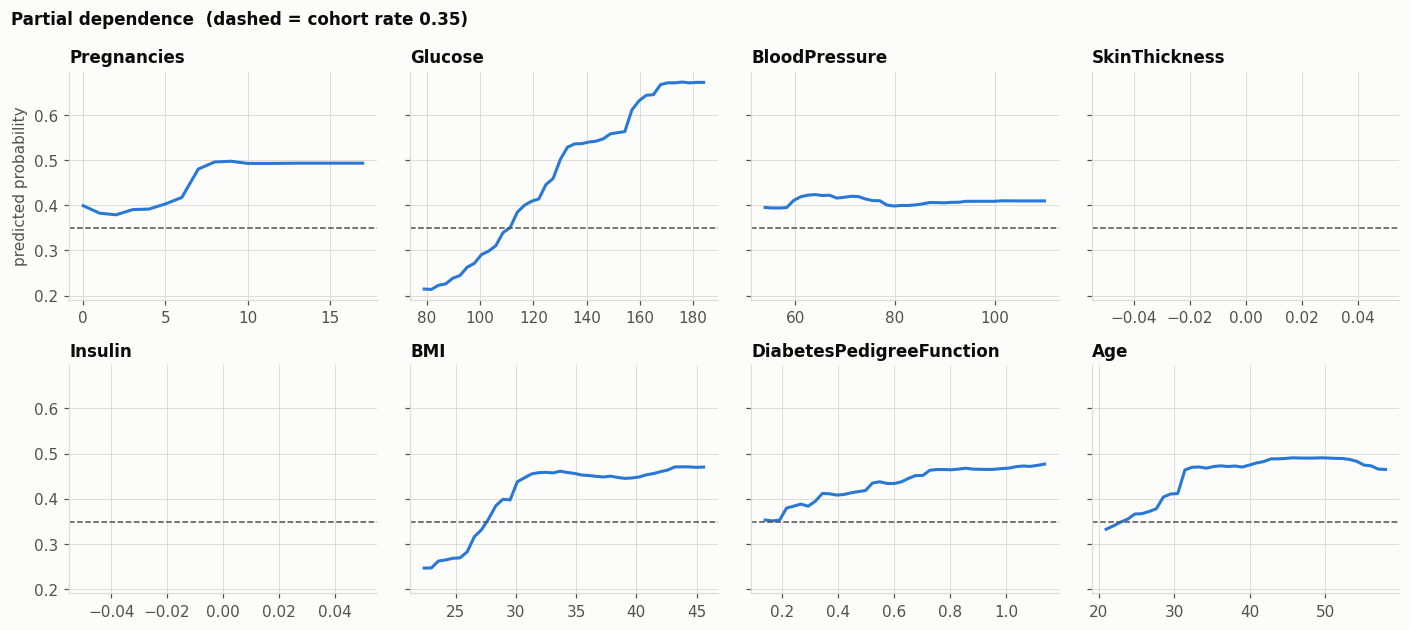

In [5]:
pdp_rf = {f: explain.partial_dependence_frame(rf, X_train, f) for f in FEATURES}
plots.partial_dependence_curves(pdp_rf, base_rate=y_train.mean());

The linear model's curves are smooth sigmoids by definition, so their shape is
assumed. The forest's are free to bend, which is what makes the comparison
useful, and the forest's glucose curve rises steadily as well. It reveals no
threshold that the linear model missed.

That is the mechanism behind notebook 3's main result. The flexible model had
the capacity to find non-linear structure and largely did not, because the
underlying relationships are close to monotone. Notebook 2's binned prevalence
curves showed as much before any model was fitted.

The forest's `Age` curve is the one visible exception, bending where the linear
model runs straight, and it is the same feature the two models weighted
differently.

## A rule summary of the forest

A global surrogate fits a shallow decision tree to reproduce the forest's
predictions, then measures how often it agrees. Fidelity decides whether the
rules are worth believing. A surrogate agreeing 90% of the time is a fair
summary, while one agreeing 60% of the time is a different model whose rules
describe nothing.

In [6]:
tree, fidelity, rules = explain.surrogate_tree(rf, X_train, max_depth=3)
print(f"fidelity: {fidelity:.1%} agreement with the random forest\n")
print(rules)

fidelity: 88.3% agreement with the random forest

|--- Glucose <= 123.5
|   |--- Age <= 30.5
|   |   |--- Pregnancies <= 7.5
|   |   |   |--- class: 0
|   |   |--- Pregnancies >  7.5
|   |   |   |--- class: 1
|   |--- Age >  30.5
|   |   |--- Glucose <= 107.5
|   |   |   |--- class: 0
|   |   |--- Glucose >  107.5
|   |   |   |--- class: 1
|--- Glucose >  123.5
|   |--- BMI <= 29.8
|   |   |--- Glucose <= 151.5
|   |   |   |--- class: 0
|   |   |--- Glucose >  151.5
|   |   |   |--- class: 1
|   |--- BMI >  29.8
|   |   |--- Age <= 31.5
|   |   |   |--- class: 1
|   |   |--- Age >  31.5
|   |   |   |--- class: 1



Fidelity is 88.3%, high enough for the rules to serve as a fair summary of the
forest. The remaining 12% is a genuine caveat and not a rounding error.

The tree splits on glucose first, then on glucose again or on BMI and age,
which matches both the permutation importances and the coefficient intervals.
Three independent methods pointing at the same small set of features is the
strongest evidence in this notebook, since they fail in different ways and agree
anyway.

## Explaining a single prediction

Global importance says what the model uses on average. It cannot say why a
specific person was flagged, which is usually the question a clinician asks. For
the linear model this decomposition is exact.

In [7]:
test_proba = lr.predict_proba(X_test)[:, 1]
threshold = evaluate.choose_threshold(
    y_train, evaluate.out_of_fold_proba(lr, X_train, y_train), criterion="f1"
)

highest = X_test.index[test_proba.argmax()]
missed = [i for i, (idx, truth) in enumerate(y_test.items())
          if truth == 1 and test_proba[i] < threshold]
missed_index = X_test.index[missed[int(np.argmin(test_proba[missed]))]]

print(f"most confident prediction : patient {highest}, p = {test_proba.max():.3f}")
print(f"worst miss (a false negative): patient {missed_index}, "
      f"p = {test_proba[X_test.index.get_loc(missed_index)]:.3f}, threshold {threshold:.2f}")

most confident prediction : patient 622, p = 0.974
worst miss (a false negative): patient 284, p = 0.232, threshold 0.43


In [8]:
confident = explain.local_contributions(lr, X_test, highest)

# the decomposition is exact, not approximate: verify it rather than claim it
assert abs(confident.attrs["probability"] - confident.attrs["model_probability"]) < 1e-9
print(f"intercept {confident.attrs['intercept']} + contributions "
      f"= log-odds {confident.attrs['log_odds']} -> p = {confident.attrs['probability']}")
print(f"model's own predict_proba          -> p = {confident.attrs['model_probability']}")
confident

intercept -0.22 + contributions = log-odds 3.616 -> p = 0.974
model's own predict_proba          -> p = 0.974


,feature,value_standardised,coefficient,contribution
0,Glucose,2.019,1.046,2.112
1,DiabetesPedigreeFunction,2.943,0.297,0.874
2,BMI,1.172,0.435,0.510
3,Pregnancies,0.615,0.395,0.243
4,Age,0.988,0.157,0.155
5,missingindicator_Insulin,1.057,0.141,0.149
6,missingindicator_SkinThickness,1.590,-0.069,-0.109
7,BloodPressure,1.791,-0.043,-0.077
8,missingindicator_BloodPressure,-0.214,0.157,-0.034
9,missingindicator_BMI,-0.107,-0.086,0.009


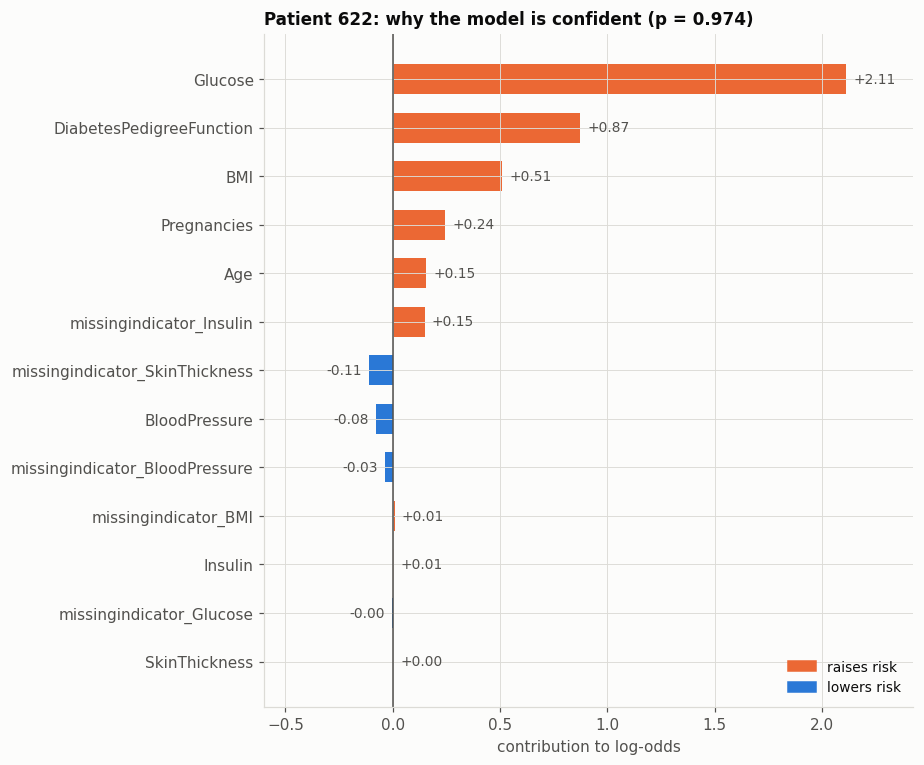

In [9]:
plots.local_contribution_bar(
    confident, f"Patient {highest}: why the model is confident (p = {confident.attrs['probability']})"
);

The model is 97% confident about this patient and the reason is legible.
Glucose 2.0 standard deviations above the mean contributes +2.11 to the
log-odds on its own, more than everything else combined. An unusually high
diabetes pedigree function (2.9 SD) adds +0.87, and BMI adds +0.51.

The assertion above confirms that the contributions plus the intercept
reproduce `predict_proba` to within floating-point error, which is what
distinguishes this from an approximation.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
284,2,108.0,80.0,NaN,NaN,27.0,0.259,52


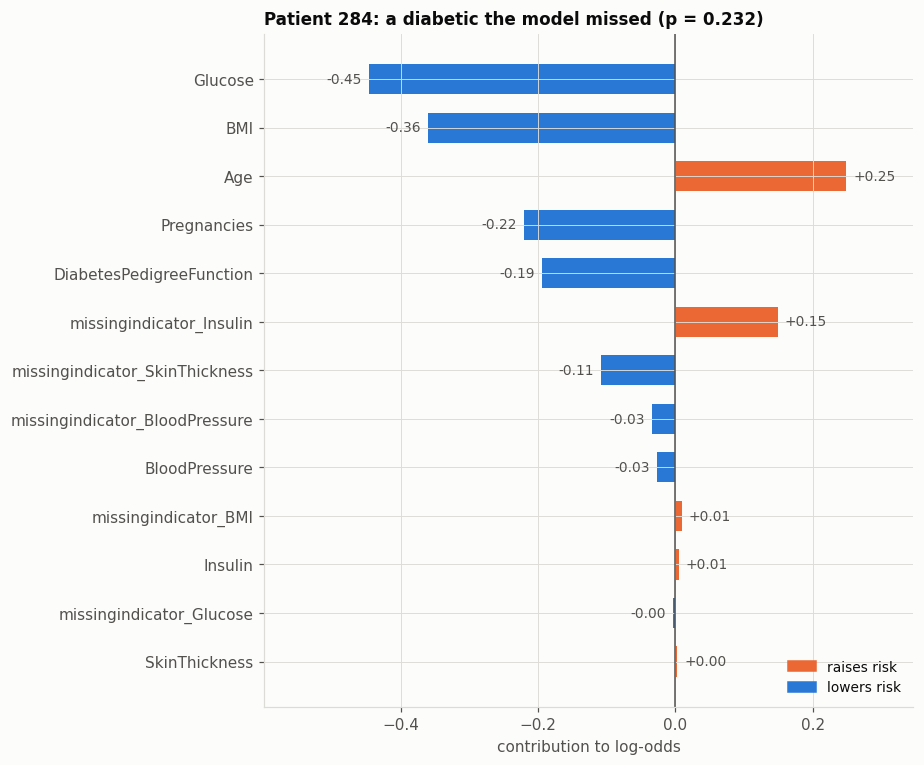

In [10]:
miss = explain.local_contributions(lr, X_test, missed_index)
plots.local_contribution_bar(
    miss, f"Patient {missed_index}: a diabetic the model missed (p = {miss.attrs['probability']})"
)
X_test.loc[[missed_index]]

This case is more useful than the confident one. The patient has diabetes and
the model ranked them below the threshold, and the breakdown shows why.

Every feature the model relies on sits below the cohort average: glucose 108
against a mean of 122, BMI 27 against 32.5, 2 pregnancies against 3.9, pedigree
function 0.26 against 0.47. The one strongly abnormal value is age 52 against a
cohort mean of 33, which is the feature whose coefficient interval straddles
zero, the one the linear model barely weights and the forest weights ten times
more heavily.

This miss is partly a consequence of the model disagreement found earlier in
this notebook. It is also the overlap from notebook 2 made concrete for one
person: diabetic and non-diabetic patients with these measurements look alike in
these eight variables. A linear model on this feature set does not catch this
patient, and the fix is more information, or a model that uses age the way the
forest does.

---
## Summary

- `Glucose` dominates every method: permutation importance, bootstrap
  coefficient intervals, and the surrogate tree's first split. Three methods
  that fail differently, agreeing.
- Only 4 of 13 coefficients have intervals excluding zero. The model
  effectively uses `Glucose`, `BMI`, `Pregnancies` and
  `DiabetesPedigreeFunction`. The missing-indicators carry nothing, which
  explains notebook 3's null ablation.
- The two models disagree about `Age` and `Pregnancies` while scoring
  identically. Equally accurate models can rely on different features, so one
  model's importances cannot be treated as the explanation.
- Partial dependence shows the forest's curves are near-monotone as well. The
  capacity for non-linearity was there and went largely unused, which is why
  notebook 3 found no winner.
- The surrogate reaches 88.3% fidelity, high enough for its rules to serve as a
  fair summary.
- The worst miss is a diabetic with unremarkable measurements, which is a
  limitation of the feature set.

### Caveats

None of this is causal. `Glucose` is close to the diagnostic criterion for
diabetes, so its dominance is largely definitional. Correlated features make
attribution ambiguous, as the `Age`/`Pregnancies` split demonstrates. Every
explanation here describes the fitted model and not the disease.

### Choosing a final model

Performance cannot choose between the four models, so interpretability does.
Logistic regression is the defensible final choice: statistically tied with the
ensembles, exactly decomposable for any individual patient, and with uncertainty
quantifiable on every coefficient. When accuracy is equal, the model you can
interrogate is the better one to ship.

Back to [1. Data processing](01_data_processing.ipynb).